<a href="https://colab.research.google.com/github/salman-zahid-11/Flight_Route_Project/blob/main/AI_Project_Flight_Routes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math, time, heapq, tracemalloc, os, urllib.request
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra as sp_dijkstra

SEED = 42
EARTH_R = 6371.0
np.random.seed(SEED)
QUICK = False   # True = fewer runs (about 1 minute); False = full experiments of the report (about 3-5 minutes)
print("pandas", pd.__version__, "| networkx", nx.__version__)

pandas 2.2.3 | networkx 3.7


In [ ]:
ROUTE_COLS = ['airline','airline_id','src','src_id','dst','dst_id','codeshare','stops','equipment']
AIRPORT_COLS = ['id','name','city','country','iata','icao','lat','lon','alt','tz','dst','tzdb','type','source']
BASE = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/"

def find_file(*names):
    for n in names:
        if os.path.exists(n): return n
    return None

def read_table(path, cols):
    hdr = None if path.endswith('.dat') else 0
    return pd.read_csv(path, header=hdr, names=cols, na_values=['\\N'], keep_default_na=False, dtype=str, encoding='utf-8')

rp = find_file('routes.csv', 'routes.dat')
ap_path = find_file('airports.dat', 'airports.csv')
for fname, found in (('routes.dat', rp), ('airports.dat', ap_path)):
    if found is None:
        try:
            print("downloading", fname, "from the OpenFlights repository ...")
            urllib.request.urlretrieve(BASE + fname, fname)
        except Exception as e:
            print("download failed:", e)
            try:
                from google.colab import files
                print("Please upload", fname); files.upload()
            except ImportError:
                raise SystemExit("Put routes.csv/routes.dat and airports.dat next to this notebook.")
rp = find_file('routes.csv', 'routes.dat')
ap_path = find_file('airports.dat', 'airports.csv')
routes_raw = read_table(rp, ROUTE_COLS)
airports_raw = read_table(ap_path, AIRPORT_COLS)
routes_raw = routes_raw.replace('', np.nan)
airports_raw = airports_raw.replace('', np.nan)
print("raw route rows:", len(routes_raw), "| raw airport rows:", len(airports_raw))

downloading routes.dat from the OpenFlights repository ...
downloading airports.dat from the OpenFlights repository ...
raw route rows: 67663 | raw airport rows: 7698


In [ ]:
log = [('Raw rows', len(routes_raw))]
r = routes_raw.copy()
# 1. convert types, missing ids -> NaN
for c in ['airline_id','src_id','dst_id','stops']:
    r[c] = pd.to_numeric(r[c], errors='coerce')
r = r.dropna(subset=['src_id','dst_id']).copy()
r[['src_id','dst_id']] = r[['src_id','dst_id']].astype(int)
log.append(('Drop rows with missing source/destination airport id', len(r)))

# 2. airports: numeric coordinates, valid ranges
ap = airports_raw.copy()
ap['id'] = pd.to_numeric(ap['id'], errors='coerce')
ap = ap.dropna(subset=['id']); ap['id'] = ap['id'].astype(int)
for c in ['lat','lon','alt']: ap[c] = pd.to_numeric(ap[c], errors='coerce')
ap = ap.dropna(subset=['lat','lon'])
ap = ap[ap.lat.between(-90, 90) & ap.lon.between(-180, 180)].drop_duplicates('id')
ap['code'] = ap['iata'].fillna(ap['icao']).fillna(ap['id'].astype(str))

# 3. keep only routes whose both airports have valid coordinates
r = r[r.src_id.isin(ap.id) & r.dst_id.isin(ap.id)]
log.append(('Drop routes whose airports are unknown / have bad coordinates', len(r)))
# 4. remove self loops
r = r[r.src_id != r.dst_id]
log.append(('Remove self-loops (src = dst)', len(r)))
# 5. unique directed airport pairs (several airlines fly the same pair)
edges = r[['src_id','dst_id']].drop_duplicates().reset_index(drop=True)
log.append(('Unique directed airport pairs (graph edges)', len(edges)))
pd.DataFrame([(s, n, 0 if i == 0 else log[i-1][1] - n) for i, (s, n) in enumerate(log)],
             columns=['Pre-processing step','Rows remaining','Rows removed'])

,Pre-processing step,Rows remaining,Rows removed
0,Raw rows,67663,0
1,Drop rows with missing source/destination airp...,67240,423
2,Drop routes whose airports are unknown / have ...,66771,469
3,Remove self-loops (src = dst),66770,1
4,Unique directed airport pairs (graph edges),36906,29864


In [ ]:
ids = sorted(set(edges.src_id) | set(edges.dst_id))
idx = {a: i for i, a in enumerate(ids)}
apx = ap.set_index('id').loc[ids]
N = len(ids)
nodes = pd.DataFrame({'id': ids, 'code': apx.code.values, 'country': apx.country.values,
                      'lat': apx.lat.values, 'lon': apx.lon.values})
LAT = np.radians(nodes.lat.values).tolist(); LON = np.radians(nodes.lon.values).tolist()

def hav(i, j):
    """great-circle distance (km) between node indices i and j"""
    dlat = LAT[j]-LAT[i]; dlon = LON[j]-LON[i]
    a = math.sin(dlat/2)**2 + math.cos(LAT[i])*math.cos(LAT[j])*math.sin(dlon/2)**2
    return 2*EARTH_R*math.asin(math.sqrt(min(1.0, a)))

eu = [idx[a] for a in edges.src_id]; ev = [idx[b] for b in edges.dst_id]
dist = [hav(u, v) for u, v in zip(eu, ev)]
adj = [[] for _ in range(N)]
for u, v, d in zip(eu, ev, dist): adj[u].append((v, d))
W = {(u, v): d for u, v, d in zip(eu, ev, dist)}
M = csr_matrix((dist, (eu, ev)), shape=(N, N))

Gu = nx.Graph(); Gu.add_nodes_from(range(N)); Gu.add_edges_from(zip(eu, ev))
nodes['degree'] = [Gu.degree(i) for i in range(N)]
deg = nodes['degree'].values
Gd = nx.DiGraph(); Gd.add_nodes_from(range(N)); Gd.add_edges_from(zip(eu, ev))
scc_nodes = sorted(max(nx.strongly_connected_components(Gd), key=len))

stats = pd.DataFrame({'Statistic': ['Airports (nodes)','Routes (edges)','Airlines','Countries','Avg. degree','Max degree',
                                    'Mean route length (km)','Longest route (km)','Largest strongly connected component'],
 'Value': [N, len(edges), r.airline.nunique(), nodes.country.nunique(), round(float(deg.mean()),2), int(deg.max()),
           round(float(np.mean(dist))), round(float(np.max(dist))), f"{len(scc_nodes)} ({100*len(scc_nodes)/N:.1f}%)"]})
stats

,Statistic,Value
0,Airports (nodes),3214
1,Routes (edges),36906
2,Airlines,566
3,Countries,225
4,Avg. degree,11.73
5,Max degree,248
6,Mean route length (km),1760
7,Longest route (km),16082
8,Largest strongly connected component,3147 (97.9%)


In [ ]:
def astar(s, t, w=1.0, use_h=True, record=False):
    """A* (w=1 optimal). use_h=False gives Dijkstra. w>1 gives weighted A*. Returns dict of metrics."""
    t0 = time.perf_counter()
    g = {s: 0.0}; parent = {s: None}; closed = set(); cnt = 0
    h0 = hav(s, t) if use_h else 0.0
    heap = [(w*h0, cnt, s)]; expanded = 0; generated = 1; max_front = 1; order = []
    while heap:
        f, _, n = heapq.heappop(heap)
        if n in closed: continue
        if n == t:
            path = []; x = n
            while x is not None: path.append(x); x = parent[x]
            return dict(path=path[::-1], cost=g[n], expanded=expanded, generated=generated, max_frontier=max_front,
                        time=time.perf_counter()-t0, order=order, found=True)
        closed.add(n); expanded += 1
        if record: order.append(n)
        gn = g[n]
        for m, d in adj[n]:
            ng = gn + d
            if ng < g.get(m, 1e18):
                g[m] = ng; parent[m] = n; cnt += 1; generated += 1
                heapq.heappush(heap, (ng + (w*hav(m, t) if use_h else 0.0), cnt, m))
                if len(heap) > max_front: max_front = len(heap)
    return dict(path=[], cost=float('inf'), expanded=expanded, generated=generated, max_frontier=max_front,
                time=time.perf_counter()-t0, order=order, found=False)

def bfs(s, t):
    """breadth-first search: fewest hops (ignores distance)"""
    t0 = time.perf_counter(); parent = {s: None}; q = [s]; expanded = 0; i = 0
    while i < len(q):
        n = q[i]; i += 1; expanded += 1
        if n == t:
            path = []; x = n
            while x is not None: path.append(x); x = parent[x]
            path = path[::-1]
            return dict(path=path, cost=sum(W[(a, b)] for a, b in zip(path, path[1:])), expanded=expanded,
                        generated=len(parent), max_frontier=len(q)-i, time=time.perf_counter()-t0, found=True)
        for m, _ in adj[n]:
            if m not in parent: parent[m] = n; q.append(m)
    return dict(path=[], cost=float('inf'), expanded=expanded, generated=len(parent), max_frontier=0,
                time=time.perf_counter()-t0, found=False)

def valid_path(p, s, t):
    return len(p) > 0 and p[0] == s and p[-1] == t and all((a, b) in W for a, b in zip(p, p[1:]))

In [ ]:
nq = 60 if QUICK else 300
rng = np.random.default_rng(SEED)
queries = [tuple(int(x) for x in rng.choice(scc_nodes, 2, replace=False)) for _ in range(nq)]
algos = {'A*': lambda s,t: astar(s,t),
         'Weighted A* (w=1.5)': lambda s,t: astar(s,t,w=1.5),
         'Dijkstra': lambda s,t: astar(s,t,use_h=False),
         'BFS': lambda s,t: bfs(s,t)}
res = {name: [f(s,t) for s,t in queries] for name,f in algos.items()}
opt = np.array([x['cost'] for x in res['Dijkstra']])

def peak_kib(f, qs):
    tracemalloc.start(); peaks = []
    for s,t in qs:
        tracemalloc.reset_peak(); f(s,t); peaks.append(tracemalloc.get_traced_memory()[1]/1024)
    tracemalloc.stop(); return np.mean(peaks)

rows = {}
for name, R in res.items():
    cost = np.array([x['cost'] for x in R])
    rows[name] = {
      'Optimal paths (%)': round(100*np.mean(np.isclose(cost, opt, rtol=1e-9)), 2),
      'Path validity (%)': round(100*np.mean([valid_path(x['path'], s, t) for x,(s,t) in zip(R, queries)]), 2),
      'Mean cost (km)': round(cost.mean(), 1),
      'Cost overhead vs optimum (%)': round(100*(cost.mean()/opt.mean()-1), 2),
      'Mean hops': round(np.mean([len(x['path'])-1 for x in R]), 2),
      'Mean nodes expanded': round(np.mean([x['expanded'] for x in R]), 1),
      'Mean nodes generated': round(np.mean([x['generated'] for x in R]), 1),
      'Mean max frontier': round(np.mean([x['max_frontier'] for x in R]), 1),
      'Mean time (ms)': round(1000*np.mean([x['time'] for x in R]), 3),
      'Peak memory (KiB, mean of 40)': round(peak_kib(algos[name], queries[:40]), 1)}
bench = pd.DataFrame(rows)
bench

,A*,Weighted A* (w=1.5),Dijkstra,BFS
Optimal paths (%),100.000,36.330,100.000,14.670
Path validity (%),100.000,100.000,100.000,100.000
Mean cost (km),9581.300,9840.000,9581.300,11352.800
Cost overhead vs optimum (%),0.000,2.700,0.000,18.490
Mean hops,4.910,4.730,4.910,3.910
Mean nodes expanded,181.000,54.800,1518.900,1538.100
Mean nodes generated,753.800,366.900,2673.200,2550.600
Mean max frontier,524.600,293.100,749.300,1012.500
Mean time (ms),3.348,1.792,12.035,7.235
"Peak memory (KiB, mean of 40)",94.700,47.400,325.700,182.200


In [ ]:
# Heuristic checks: admissibility, tightness and consistency
viol_adm = sum(hav(s,t) > c + 1e-6 for (s,t), c in zip(queries, opt))
tight = np.array([hav(s,t)/c for (s,t), c in zip(queries, opt) if c > 0])
print(f"Admissibility: h(origin) > true cost in {viol_adm} of {len(queries)} queries (expected 0)")
print(f"Tightness h/true-cost: mean {tight.mean():.3f}, min {tight.min():.3f}")
targets = [int(x) for x in np.random.default_rng(SEED).choice(scc_nodes, 5, replace=False)]
bad = checks = 0
for t in targets:
    for u, v, d in zip(eu, ev, dist):
        checks += 1
        if hav(u, t) > d + hav(v, t) + 1e-6: bad += 1
print(f"Consistency: h(n) <= w(n,m) + h(m) violated on {bad} of {checks} edge checks (expected 0)")

Admissibility: h(origin) > true cost in 0 of 300 queries (expected 0)
Tightness h/true-cost: mean 0.869, min 0.261
Consistency: h(n) <= w(n,m) + h(m) violated on 0 of 184530 edge checks (expected 0)


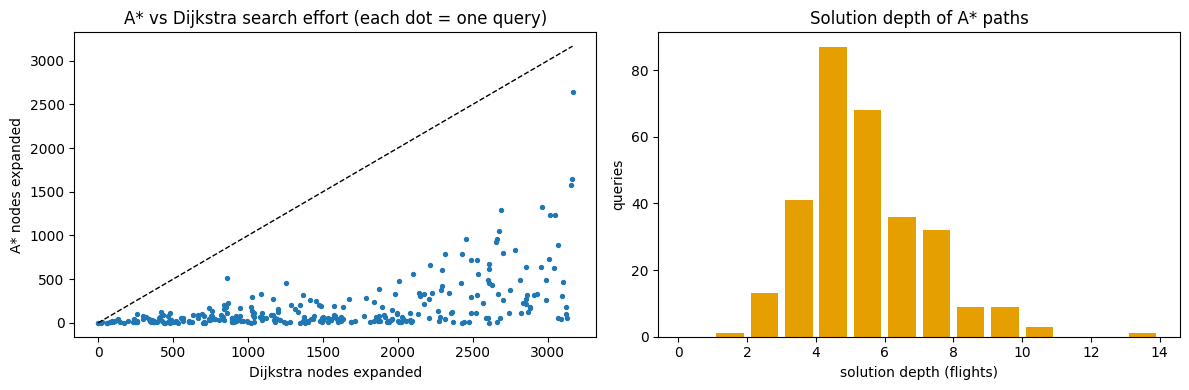

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter([x['expanded'] for x in res['Dijkstra']], [x['expanded'] for x in res['A*']], s=8)
mx = max(x['expanded'] for x in res['Dijkstra']); ax[0].plot([0, mx], [0, mx], 'k--', lw=1)
ax[0].set_xlabel('Dijkstra nodes expanded'); ax[0].set_ylabel('A* nodes expanded'); ax[0].set_title('A* vs Dijkstra search effort (each dot = one query)')
depth = [len(x['path'])-1 for x in res['A*']]
ax[1].hist(depth, bins=range(0, max(depth)+2), rwidth=.8, color='#E69F00'); ax[1].set_xlabel('solution depth (flights)'); ax[1].set_ylabel('queries'); ax[1].set_title('Solution depth of A* paths')
plt.tight_layout(); plt.show()

In [ ]:
code2i = {c: i for i, c in enumerate(nodes.code)}
pairs = [('DAC','JFK'),('DAC','LHR'),('JFK','SYD'),('LHR','HND'),('DXB','LAX'),('GRU','PEK'),('CDG','JNB')]
rows = []
for a, b in pairs:
    if a in code2i and b in code2i and code2i[a] in set(scc_nodes) and code2i[b] in set(scc_nodes):
        s, t = code2i[a], code2i[b]; x = astar(s, t); dj = astar(s, t, use_h=False); bf = bfs(s, t)
        rows.append((a, b, ' -> '.join(nodes.code[p] for p in x['path']), round(x['cost']), len(x['path'])-1, x['expanded'], dj['expanded'], round(bf['cost'])))
pd.DataFrame(rows, columns=['From','To','A* path','A* km','Flights','A* expanded','Dijkstra expanded','BFS km'])

,From,To,A* path,A* km,Flights,A* expanded,Dijkstra expanded,BFS km
0,DAC,JFK,DAC -> DEL -> JFK,13180,2,22,2053,14538
1,DAC,LHR,DAC -> LHR,8015,1,1,1340,8015
2,JFK,SYD,JFK -> LAX -> SYD,16035,2,21,2983,23093
3,LHR,HND,LHR -> HND,9591,1,1,2332,9591
4,DXB,LAX,DXB -> LAX,13400,1,1,2606,13400
5,GRU,PEK,GRU -> MXP -> PEK,17577,2,8,2848,18642
6,CDG,JNB,CDG -> JNB,8738,1,1,1935,8738


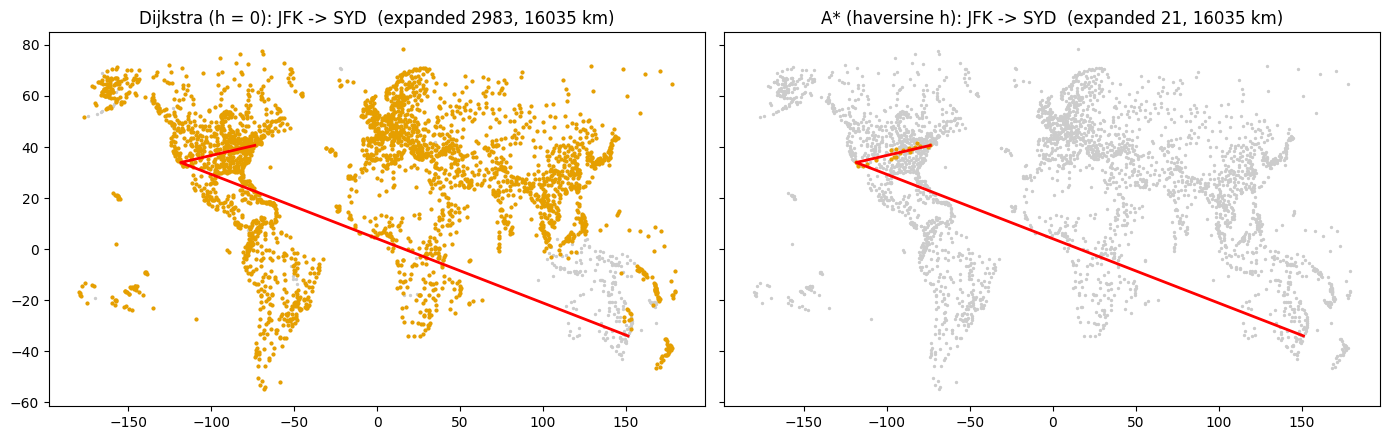

In [ ]:
if 'JFK' in code2i and 'SYD' in code2i:
    s, t = code2i['JFK'], code2i['SYD']
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for a, (title, kw) in zip(ax, [('Dijkstra (h = 0): JFK -> SYD', dict(use_h=False)), ('A* (haversine h): JFK -> SYD', dict())]):
        x = astar(s, t, record=True, **kw)
        a.scatter(nodes.lon, nodes.lat, s=2, c='#cccccc')
        a.scatter(nodes.lon[x['order']], nodes.lat[x['order']], s=4, c='#E69F00')
        a.plot(nodes.lon[x['path']], nodes.lat[x['path']], 'r-', lw=2)
        a.set_title(f"{title}  (expanded {x['expanded']}, {x['cost']:.0f} km)")
    plt.tight_layout(); plt.show()

In [ ]:
def pick_cities(K, seed, min_deg=15):
    rg = np.random.default_rng(seed)
    pool = [i for i in scc_nodes if deg[i] >= min_deg]
    rg.shuffle(pool); chosen = []; used_c = set()
    for i in pool:
        c = nodes.country[i]
        if c not in used_c: chosen.append(i); used_c.add(c)
        if len(chosen) == K: break
    return np.array(chosen)

def cost_matrix(cities):
    return sp_dijkstra(M, directed=True, indices=cities)[:, cities]

def tour_cost(D, perm):
    full = np.concatenate([[0], perm, [0]]); return D[full[:-1], full[1:]].sum()

def held_karp(D):
    """exact optimum of the closed asymmetric TSP, city 0 = start"""
    n = D.shape[0]; m = n-1; Dm = D[1:, 1:]
    dp = np.full((1 << m, m), np.inf)
    for j in range(m): dp[1 << j, j] = D[0, j+1]
    for mask in range(1, 1 << m):
        for j in range(m):
            if mask & (1 << j) and mask != (1 << j):
                prev = mask ^ (1 << j)
                dp[mask, j] = np.min(dp[prev] + Dm[:, j])
    return float(np.min(dp[(1 << m)-1] + D[1:, 0]))

def order_crossover(p1, p2, rg):
    m = len(p1); a, b = sorted(rg.choice(m+1, 2, replace=False))
    child = np.empty(m, dtype=int); child[a:b] = p1[a:b]
    seg = set(p1[a:b].tolist()); rest = [x for x in p2 if x not in seg]
    child[:a] = rest[:a]; child[b:] = rest[a:]; return child

def mutate(c, rg, pm):
    if rg.random() < pm:
        i, j = sorted(rg.choice(len(c), 2, replace=False))
        if rg.random() < .5: c[i], c[j] = c[j], c[i]
        else: c[i:j+1] = c[i:j+1][::-1]
    return c

def genetic_algorithm(D, pop_size=200, gens=300, pc=0.9, pm=0.25, elite=2, tk=3, seed=0):
    rg = np.random.default_rng(seed); n = D.shape[0]; m = n-1; t0 = time.perf_counter()
    pop = np.array([rg.permutation(m)+1 for _ in range(pop_size)])
    zeros = np.zeros((pop_size, 1), dtype=int)
    def costs(P):
        full = np.hstack([zeros[:len(P)], P, zeros[:len(P)]]); return D[full[:, :-1], full[:, 1:]].sum(1)
    hist = []; best_c = np.inf; best = None; found_at = 0; evals = 0
    for g in range(gens):
        fit = costs(pop); evals += pop_size; order = np.argsort(fit)
        if fit[order[0]] < best_c - 1e-9: best_c = fit[order[0]]; best = pop[order[0]].copy(); found_at = g
        hist.append(best_c)
        new = [pop[i].copy() for i in order[:elite]]
        while len(new) < pop_size:
            cand = rg.integers(0, pop_size, (2, tk))
            p1 = pop[cand[0][np.argmin(fit[cand[0]])]]; p2 = pop[cand[1][np.argmin(fit[cand[1]])]]
            c = order_crossover(p1, p2, rg) if rg.random() < pc else p1.copy()
            new.append(mutate(c, rg, pm))
        pop = np.array(new)
    return dict(best=best, cost=best_c, hist=np.array(hist), found_at=found_at, evals=evals, time=time.perf_counter()-t0)

def nearest_neighbour(D, start=0):
    n = D.shape[0]; tour = [start]; left = set(range(n)) - {start}
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j]); tour.append(nxt); left.remove(nxt)
    return np.array(tour[1:])

def two_opt(D, perm):
    best = perm.copy(); bc = tour_cost(D, best); improved = True
    while improved:
        improved = False
        for i in range(len(best)-1):
            for j in range(i+1, len(best)):
                cand = best.copy(); cand[i:j+1] = cand[i:j+1][::-1]; cc = tour_cost(D, cand)
                if cc < bc - 1e-9: best, bc, improved = cand, cc, True
    return best

def random_search(D, evals, seed=0):
    rg = np.random.default_rng(seed); m = D.shape[0]-1; best = np.inf
    for _ in range(evals): best = min(best, tour_cost(D, rg.permutation(m)+1))
    return best

In [ ]:
K16 = 16
cities16 = pick_cities(K16, SEED); D16 = cost_matrix(cities16)
t0 = time.perf_counter(); opt16 = held_karp(D16)
print(f"Exact optimum (Held-Karp, {K16} cities): {opt16:,.1f} km  [{time.perf_counter()-t0:.1f} s]")
runs16 = 5 if QUICK else 20
G16 = [genetic_algorithm(D16, pop_size=200, gens=300, pc=.9, pm=.25, elite=2, tk=3, seed=s) for s in range(runs16)]
c16 = np.array([g['cost'] for g in G16])
pd.Series({'Exact optimum (km)': round(opt16, 1), 'GA best (km)': round(c16.min(), 1), 'GA mean (km)': round(c16.mean(), 1),
           'GA worst (km)': round(c16.max(), 1), 'Std (km)': round(c16.std(), 2),
           'Solution quality - mean (%)': round(100*np.mean(opt16/c16), 2),
           f'Optimum found (runs of {runs16})': int(np.sum(c16 <= opt16 + 1e-6)),
           'Mean generations to best': round(np.mean([g['found_at'] for g in G16]), 1),
           'Mean time / run (s)': round(np.mean([g['time'] for g in G16]), 3),
           'Evaluations / run': G16[0]['evals']}, name='GA, 16 cities').to_frame()

Exact optimum (Held-Karp, 16 cities): 54,365.9 km  [1.0 s]


,"GA, 16 cities"
Exact optimum (km),54365.900
GA best (km),54365.900
GA mean (km),54496.500
GA worst (km),55672.100
Std (km),391.860
Solution quality - mean (%),99.770
Optimum found (runs of 20),18.000
Mean generations to best,91.600
Mean time / run (s),2.542
Evaluations / run,60000.000


In [ ]:
K30 = 30
cities30 = pick_cities(K30, SEED); D30 = cost_matrix(cities30)
pop30, gens30 = (200, 200) if QUICK else (300, 600)
runs30 = 3 if QUICK else 10
G30 = [genetic_algorithm(D30, pop_size=pop30, gens=gens30, seed=s) for s in range(runs30)]
c30 = np.array([g['cost'] for g in G30])
nn = nearest_neighbour(D30); nn_c = tour_cost(D30, nn)
t0 = time.perf_counter(); two = two_opt(D30, nn); two_c = tour_cost(D30, two); t_two = time.perf_counter()-t0
t0 = time.perf_counter(); rs_c = random_search(D30, pop30*gens30, seed=SEED); t_rs = time.perf_counter()-t0
best_known = min(c30.min(), two_c, nn_c, rs_c)
tab = pd.DataFrame([
 ('Genetic algorithm (best of runs)', c30.min(), np.mean([g['time'] for g in G30]), 100*best_known/c30.min()),
 ('Genetic algorithm (mean of runs)', c30.mean(), np.mean([g['time'] for g in G30]), 100*best_known/c30.mean()),
 ('Nearest neighbour', nn_c, 0.0, 100*best_known/nn_c),
 ('Nearest neighbour + 2-opt', two_c, t_two, 100*best_known/two_c),
 ('Random search (same #evaluations)', rs_c, t_rs, 100*best_known/rs_c)],
 columns=['Method','Tour cost (km)','Time (s)','Quality vs best known (%)']).round(2)
print(f"Best GA tour is {100*(1-c30.min()/two_c):.1f}% shorter than NN + 2-opt")
tab

Best GA tour is 5.1% shorter than NN + 2-opt


,Method,Tour cost (km),Time (s),Quality vs best known (%)
0,Genetic algorithm (best of runs),88256.36,7.84,100.00
1,Genetic algorithm (mean of runs),90880.24,7.84,97.11
2,Nearest neighbour,98798.25,0.00,89.33
3,Nearest neighbour + 2-opt,93015.59,0.01,94.88
4,Random search (same #evaluations),190789.84,1.71,46.26


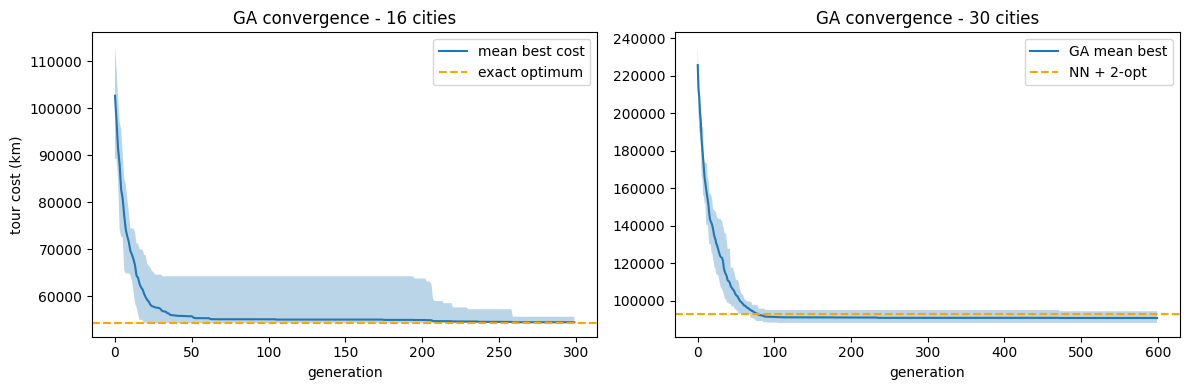

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
H = np.array([g['hist'] for g in G16]); x = np.arange(H.shape[1])
ax[0].fill_between(x, H.min(0), H.max(0), alpha=.3); ax[0].plot(x, H.mean(0), label='mean best cost'); ax[0].axhline(opt16, color='orange', ls='--', label='exact optimum')
ax[0].set_title('GA convergence - 16 cities'); ax[0].set_xlabel('generation'); ax[0].set_ylabel('tour cost (km)'); ax[0].legend()
H = np.array([g['hist'] for g in G30]); x = np.arange(H.shape[1])
ax[1].fill_between(x, H.min(0), H.max(0), alpha=.3); ax[1].plot(x, H.mean(0), label='GA mean best'); ax[1].axhline(two_c, color='orange', ls='--', label='NN + 2-opt')
ax[1].set_title('GA convergence - 30 cities'); ax[1].set_xlabel('generation'); ax[1].legend()
plt.tight_layout(); plt.show()

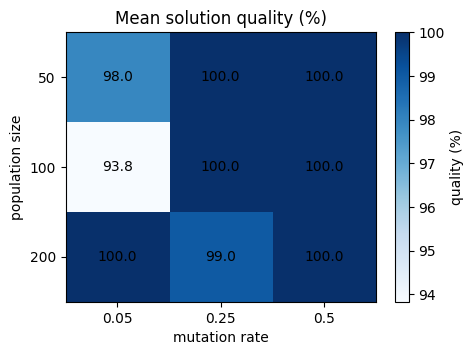

,Population,Mutation rate,Mean quality (%),Optimum found,Mean time (s)
0,50,0.05,97.95,2/5,0.422
1,50,0.25,100.00,5/5,0.475
2,50,0.50,100.00,5/5,0.425
3,100,0.05,93.83,3/5,0.697
4,100,0.25,100.00,5/5,0.920
5,100,0.50,100.00,5/5,0.869
6,200,0.05,100.00,5/5,1.566
7,200,0.25,98.99,4/5,1.553
8,200,0.50,100.00,5/5,1.853


In [ ]:
pops, pms, seeds = [50, 100, 200], [0.05, 0.25, 0.5], (range(2) if QUICK else range(5))
rows = []
for p in pops:
    for pm_ in pms:
        rr = [genetic_algorithm(D16, pop_size=p, gens=200, pm=pm_, seed=s) for s in seeds]
        cc = np.array([g['cost'] for g in rr])
        rows.append((p, pm_, round(100*np.mean(opt16/cc), 2), f"{int(np.sum(cc <= opt16+1e-6))}/{len(cc)}", round(np.mean([g['time'] for g in rr]), 3)))
grid = pd.DataFrame(rows, columns=['Population','Mutation rate','Mean quality (%)','Optimum found','Mean time (s)'])
piv = grid.pivot(index='Population', columns='Mutation rate', values='Mean quality (%)')
plt.figure(figsize=(5, 3.5)); plt.imshow(piv.values, cmap='Blues', aspect='auto')
plt.xticks(range(3), piv.columns); plt.yticks(range(3), piv.index); plt.colorbar(label='quality (%)')
for i in range(3):
    for j in range(3): plt.text(j, i, f"{piv.values[i,j]:.1f}", ha='center', va='center')
plt.xlabel('mutation rate'); plt.ylabel('population size'); plt.title('Mean solution quality (%)'); plt.show()
grid

In [ ]:
def build_csp(n):
    top = nodes.sort_values('degree', ascending=False).index[:n].tolist()
    Hs = Gu.subgraph(top); pos_ = {v: i for i, v in enumerate(top)}
    adjl = [[pos_[u] for u in Hs[v]] for v in top]
    return top, adjl, Hs

def csp_solve(adjl, k, mode, limit=200_000):
    n = len(adjl); full = (1 << k)-1; t0 = time.perf_counter()
    assign = [-1]*n; dom = [full]*n; st = {'nodes': 0, 'backtracks': 0}
    adjm = [sum(1 << u for u in adjl[v]) for v in range(n)]
    pc = lambda x: bin(x).count('1')
    class Limit(Exception): pass
    def select():
        if mode != 'fc_mrv': return next(i for i in range(n) if assign[i] < 0)
        best, bc, bd = -1, 99, -1
        for v in range(n):
            if assign[v] < 0:
                c = pc(dom[v]); d = pc(adjm[v])
                if c < bc or (c == bc and d > bd): best, bc, bd = v, c, d
        return best
    def rec(done):
        if done == n: return True
        v = select(); d = dom[v]
        while d:
            lb = d & -d; d ^= lb; c = lb.bit_length()-1; st['nodes'] += 1
            if st['nodes'] > limit: raise Limit
            if mode == 'bt':
                if any(assign[u] == c for u in adjl[v]): continue
                assign[v] = c
                if rec(done+1): return True
                assign[v] = -1
            else:
                assign[v] = c; saved = []; ok = True
                for u in adjl[v]:
                    if assign[u] < 0 and dom[u] & lb:
                        saved.append((u, dom[u])); dom[u] &= ~lb
                        if dom[u] == 0: ok = False; break
                if ok and rec(done+1): return True
                for u, dd in saved: dom[u] = dd
                assign[v] = -1
            st['backtracks'] += 1
        return False
    try: solved = rec(0); status = 'solved' if solved else 'unsatisfiable'
    except Limit: solved = False; status = 'limit'
    return dict(status=status, assign=assign[:], time=time.perf_counter()-t0, **st)

def violations(adjl, assign):
    return sum(1 for v in range(len(adjl)) for u in adjl[v] if u > v and assign[u] == assign[v]) + sum(a < 0 for a in assign)

In [ ]:
ns = [10, 20, 30, 40, 50, 60, 80, 100]
modes = [('BT', 'bt'), ('FC', 'fc'), ('FC + MRV', 'fc_mrv')]
rows = []
for n in ns:
    top, adjl, Hs = build_csp(n)
    k = max(nx.coloring.greedy_color(Hs, strategy='DSATUR').values()) + 1
    for lab, mode in modes:
        o = csp_solve(adjl, k, mode)
        v = violations(adjl, o['assign']) if o['status'] == 'solved' else None
        rows.append((n, k, lab, o['status'], o['nodes'], o['backtracks'], round(o['time'], 4), v if v is not None else '-'))
csp_tab = pd.DataFrame(rows, columns=['n','k','Solver','Status','Assignments','Back-tracks','Time (s)','Violations'])
csp_tab

,n,k,Solver,Status,Assignments,Back-tracks,Time (s),Violations
0,10,7,BT,solved,39,0,0.0001,0
1,10,7,FC,solved,10,0,0.0001,0
2,10,7,FC + MRV,solved,10,0,0.0001,0
3,20,11,BT,solved,102,0,0.0003,0
4,20,11,FC,solved,20,0,0.0002,0
5,20,11,FC + MRV,solved,20,0,0.0002,0
6,30,15,BT,solved,218,0,0.0004,0
7,30,15,FC,solved,30,0,0.0002,0
8,30,15,FC + MRV,solved,30,0,0.0004,0
9,40,17,BT,solved,7338,412,0.0082,0


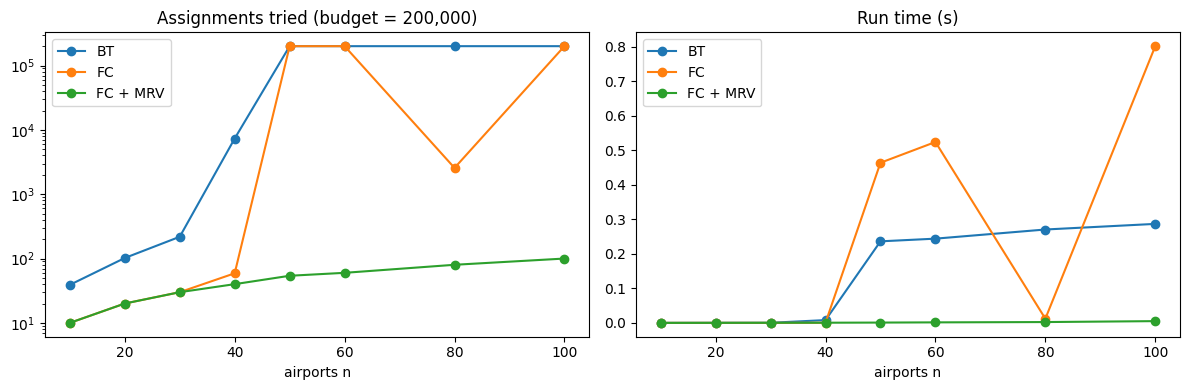

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lab, mode in modes:
    d = csp_tab[csp_tab.Solver == lab]
    ax[0].plot(d.n, d.Assignments, 'o-', label=lab); ax[1].plot(d.n, d['Time (s)'], 'o-', label=lab)
ax[0].set_yscale('log'); ax[0].set_title('Assignments tried (budget = 200,000)'); ax[1].set_title('Run time (s)')
for a in ax: a.set_xlabel('airports n'); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for n in ns:
    top, adjl, Hs = build_csp(n)
    dsat = max(nx.coloring.greedy_color(Hs, strategy='DSATUR').values()) + 1
    omega = max(len(c) for c in nx.find_cliques(Hs))
    found = None
    for k in range(omega, dsat + 1):
        o = csp_solve(adjl, k, 'fc_mrv')
        if o['status'] == 'solved': found = (k, violations(adjl, o['assign'])); break
    rows.append((n, omega, dsat, found[0] if found else '-', (found[0] == omega) if found else '-', found[1] if found else '-'))
pd.DataFrame(rows, columns=['n','Lower bound (clique)','DSATUR k','Smallest k found','Equals lower bound?','Violations'])

,n,Lower bound (clique),DSATUR k,Smallest k found,Equals lower bound?,Violations
0,10,7,7,7,True,0
1,20,11,11,11,True,0
2,30,14,15,14,True,0
3,40,17,17,17,True,0
4,50,18,18,18,True,0
5,60,18,18,18,True,0
6,80,20,21,21,False,0
7,100,22,22,22,True,0


In [ ]:
a_row = bench['A*']; d_row = bench['Dijkstra']
summary = pd.DataFrame({
 'Algorithm': ['A*', 'Genetic Algorithm', 'Forward Checking + MRV'],
 'Problem': ['Shortest path', 'Multi-city tour', 'Slot assignment (CSP)'],
 'Accuracy / guarantee': [f"{a_row['Optimal paths (%)']}% optimal paths",
                          f"{100*np.mean(opt16/c16):.2f}% of exact optimum; optimum in {int(np.sum(c16 <= opt16+1e-6))}/{len(c16)} runs",
                          f"{int((csp_tab[csp_tab.Solver=='FC + MRV'].Violations==0).sum())}/{len(ns)} sizes solved, 0 violations"],
 'Typical cost': [f"{a_row['Mean nodes expanded']} nodes, {a_row['Mean time (ms)']} ms",
                  f"{G16[0]['evals']:,} evaluations, {np.mean([g['time'] for g in G16]):.2f} s",
                  f"{int(csp_tab[(csp_tab.Solver=='FC + MRV')&(csp_tab.n==100)].Assignments.iloc[0])} assignments at n=100"]})
print(f"A* expands {100*(1-a_row['Mean nodes expanded']/d_row['Mean nodes expanded']):.0f}% fewer nodes than Dijkstra and is {d_row['Mean time (ms)']/a_row['Mean time (ms)']:.1f}x faster.")
summary

A* expands 88% fewer nodes than Dijkstra and is 3.6x faster.


,Algorithm,Problem,Accuracy / guarantee,Typical cost
0,A*,Shortest path,100.0% optimal paths,"181.0 nodes, 3.348 ms"
1,Genetic Algorithm,Multi-city tour,99.77% of exact optimum; optimum in 18/20 runs,"60,000 evaluations, 2.54 s"
2,Forward Checking + MRV,Slot assignment (CSP),"8/8 sizes solved, 0 violations",100 assignments at n=100
